<a href="https://colab.research.google.com/github/IvyWanjiru/EcoSort-Waste-Management-Assistance/blob/main/waste_management_summative_fixed_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoSort Waste Management Assistant
# Module 8 Summative Lab

## Overview

You are a data scientist at "EcoSort," a technology company that specializes in developing AI solutions for waste management. EcoSort has partnered with Metro City's waste management department to develop an intelligent waste management assistant that can help residents properly dispose of waste items so less time is spent sorting material at facilities.

This assistant needs to:

1. Identify waste materials from images uploaded by residents (CNN)
2. Classify waste items based on text descriptions provided by residents (RNN/Transformer)
3. Generate specific recycling instructions based on identified waste type and city policies (Generative Transformer with RAG)

Your task is to build this integrated system using the RealWaste dataset along with generated text data that simulates real-world waste management operations.

## Part 1: Dataset Exploration and Preparation

In this section, you will explore and prepare the datasets for your models.

### 1.1 Load and Explore the RealWaste Dataset

In [ ]:
# Verify optional NLP libraries
try:
    import transformers
    from sentence_transformers import SentenceTransformer
    print(f"Transformers version: {transformers.__version__}")
    print("SentenceTransformers successfully loaded.")
except ImportError:
    print("NLP libraries not found. Run: !pip install -q transformers sentence-transformers")

NLP libraries not found. Run: !pip install -q transformers sentence-transformers


In [ ]:
%pip install -q transformers sentence-transformers

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [ ]:
%pip install tensorflow

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/351.2 MB 1.6 MB/s eta 0:03:47
   ---------------------------------------- 1.3/351.2 MB 2.6 MB/s eta 0:02:14
   ---------------------------------------- 2.6/351.2 MB 3.9 MB/s eta 0:01:31
   ---------------------------------------- 3.1/351.2 MB 3.8 MB/s eta 0:01:31
   ---------------------------------------- 3.9/351.2 MB 3.6 MB/s eta 0:01:37
    --------------------------------------- 4.5/351.2 MB 3.5 MB/s eta 0:01:38
    --------------------------------------- 5.0/351.2 MB 3.6 MB/s eta 0:01:38
    --------------------------------------- 5.8/351.2 MB 3.3 MB/s eta 0:01:44
    --------------------------------------- 6.3/351.2 MB 3.3 MB/s eta 0:01:46
    --------------------------------------- 6.8/351.2 MB 3.2 MB/s eta 0:01:47
    ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.51.0 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [ ]:
# Import necessary libraries

import os, re, json, time, random, pathlib, warnings, functools, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)
random.seed(42)

print('GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: no GPU. In Colab use Runtime > Change runtime type > T4 GPU, otherwise CNN/T5 training is ~10x slower.')

GPUs: []


In [ ]:
# Locate a COMPLETE copy of RealWaste (works on Colab or locally); download it to LOCAL disk if missing/incomplete.
# Reading thousands of images from Google Drive is slow and uploads often stop part-way, so a local copy is preferred.
# (Optional: from google.colab import drive; drive.mount('/content/drive') -- then a complete Drive copy is also found.)
import urllib.request, zipfile
EXPECTED_IMAGES = 4752                      # RealWaste: 9 classes, 4,752 images
MIN_IMAGES = int(0.99 * EXPECTED_IMAGES)

def count_images(root):
    return sum(1 for p in pathlib.Path(root).glob('*/*') if p.suffix.lower() in {'.jpg', '.jpeg', '.png'})

def find_realwaste_dir():
    cands = [pathlib.Path(p) for p in ['RealWaste', 'realwaste-main/RealWaste', '/content/RealWaste',
                                       '/content/realwaste-main/RealWaste', '/content/drive/MyDrive/RealWaste']]
    cands += [p.parent for p in pathlib.Path('.').rglob('Cardboard') if p.is_dir()]
    for c in cands:
        if (c / 'Cardboard').is_dir() and count_images(c) >= MIN_IMAGES:
            return c
    return None

DATA_DIR = find_realwaste_dir()
if DATA_DIR is None:
    print('No complete RealWaste copy found - downloading (~650 MB) ...')
    urllib.request.urlretrieve('https://archive.ics.uci.edu/static/public/908/realwaste.zip', 'realwaste.zip')
    with zipfile.ZipFile('realwaste.zip') as z: z.extractall('.')
    DATA_DIR = find_realwaste_dir()
assert DATA_DIR is not None, 'RealWaste is still missing or incomplete (expected 4,752 images in 9 class folders).'
print('Using', DATA_DIR.resolve(), '->', count_images(DATA_DIR), 'images')

Using C:\Users\BEST\Downloads\New folder\RealWaste -> 4752 images


Cardboard              461
Food Organics          411
Glass                  420
Metal                  790
Miscellaneous Trash    495
Paper                  500
Plastic                921
Textile Trash          318
Vegetation             436

Total images: 4752  |  classes: 9
Imbalance ratio (largest / smallest class): 2.90


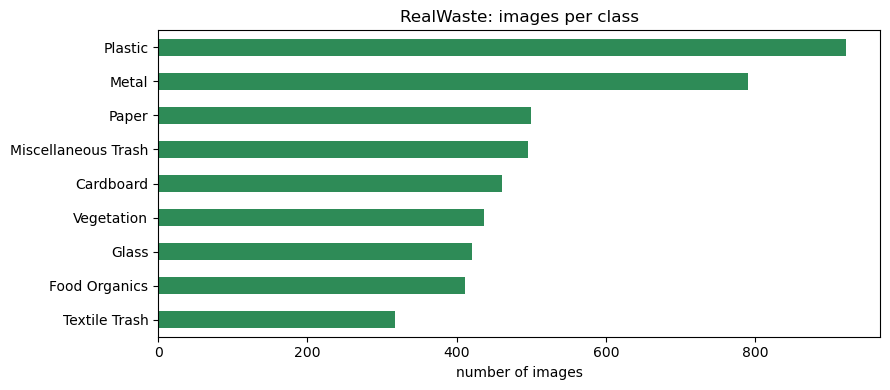

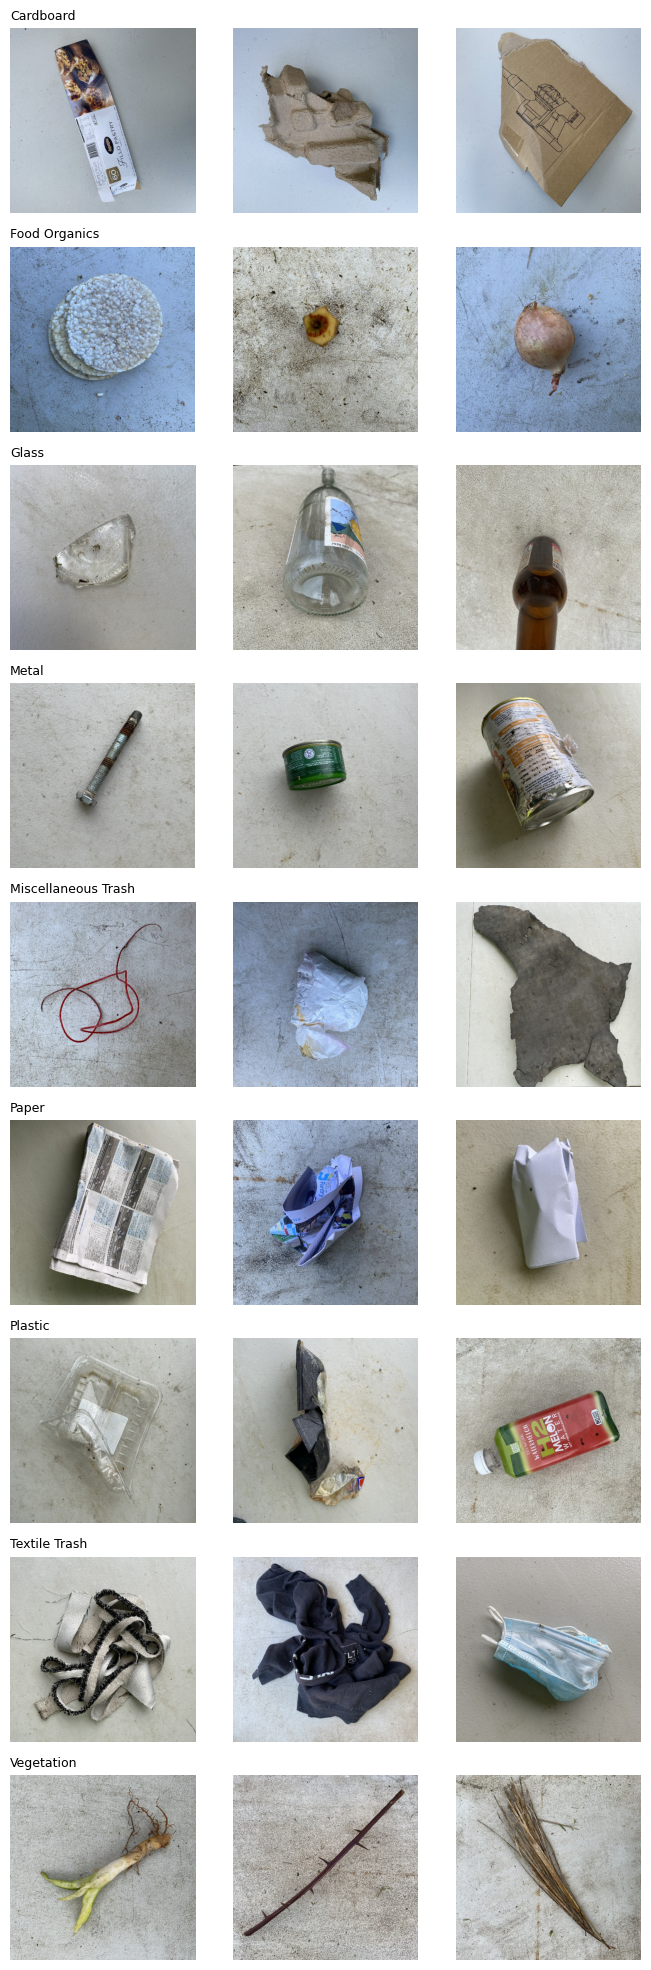

Distinct (width, height) pairs in the sample:
 width  height
524    524       540

Per-class means (brightness / contrast of the whole image, brightness of the 20px border):
                     brightness   contrast  border_brightness  file_kb
cls                                                                   
Cardboard            156.399994  48.200001         175.000000    119.5
Food Organics        156.300003  47.700001         171.199997    181.8
Glass                160.800003  35.099998         171.699997    116.0
Metal                154.800003  44.299999         171.800003    121.6
Miscellaneous Trash  160.899994  44.599998         176.800003    148.1
Paper                150.899994  45.700001         159.100006    131.0
Plastic              159.699997  37.000000         168.800003    131.9
Textile Trash        157.300003  50.200001         181.699997    132.3
Vegetation           158.500000  57.400002         183.199997    199.0


In [ ]:
# 1.1  Load and explore the RealWaste dataset
# DATA_DIR is set (and verified complete) in the cell above
IMG_EXTS = {'.jpg', '.jpeg', '.png'}
assert DATA_DIR.exists(), ("RealWaste folder not found. Download it from the UCI repository, unzip it and "
                           "place the class folders in a folder called 'RealWaste' next to this notebook.")

# --- Dataset structure: one sub-folder per class ------------------------------------------------
class_dirs = sorted(d for d in DATA_DIR.iterdir() if d.is_dir())
files_by_class = {d.name: sorted(p for p in d.iterdir() if p.suffix.lower() in IMG_EXTS) for d in class_dirs}
class_counts = pd.Series({k: len(v) for k, v in files_by_class.items()})
print(class_counts.to_string())
print(f"\nTotal images: {class_counts.sum()}  |  classes: {len(class_counts)}")
print(f"Imbalance ratio (largest / smallest class): {class_counts.max() / class_counts.min():.2f}")

# --- Distribution of categories ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4))
class_counts.sort_values().plot.barh(ax=ax, color='seagreen')
ax.set_title('RealWaste: images per class'); ax.set_xlabel('number of images')
plt.tight_layout(); plt.show()

# --- Visual inspection: 3 random examples per class -----------------------------------------------
rng = np.random.default_rng(42)
fig, axes = plt.subplots(len(files_by_class), 3, figsize=(7, 2.2 * len(files_by_class)))
for r, (cls, paths) in enumerate(files_by_class.items()):
    for c, p in enumerate(rng.choice(paths, 3, replace=False)):
        axes[r, c].imshow(Image.open(p).convert('RGB')); axes[r, c].axis('off')
        if c == 0: axes[r, c].set_title(cls, loc='left', fontsize=9)
plt.tight_layout(); plt.show()

# --- Image characteristics: resolution, brightness/contrast, background -------------------------
# Measured on a random sample of up to 60 images per class (fast, and representative enough).
rows = []
for cls, paths in files_by_class.items():
    for p in rng.choice(paths, min(60, len(paths)), replace=False):
        img = Image.open(p).convert('RGB'); a = np.asarray(img, dtype=np.float32)
        border = np.concatenate([a[:20].reshape(-1, 3), a[-20:].reshape(-1, 3),
                                 a[:, :20].reshape(-1, 3), a[:, -20:].reshape(-1, 3)])
        rows.append(dict(cls=cls, width=img.size[0], height=img.size[1],
                         brightness=a.mean(), contrast=a.std(),
                         border_brightness=border.mean(), file_kb=os.path.getsize(p) / 1024))
img_stats = pd.DataFrame(rows)
print("Distinct (width, height) pairs in the sample:\n", img_stats.groupby(['width', 'height']).size().to_string())
print("\nPer-class means (brightness / contrast of the whole image, brightness of the 20px border):")
print(img_stats.groupby('cls')[['brightness', 'contrast', 'border_brightness', 'file_kb']].mean().round(1).to_string())

### 1.2 Explore Text Datasets

shape: (5000, 5)
                                           description       category                               disposal_instruction                                                       common_confusion                                                 material_composition
0                             soiled silver tablecloth  Textile Trash  Look for textile recycling programs in your area.                                                                    NaN    Fabric made from natural or synthetic fibers, may include blends.
1                          folded glass bottle leaking          Glass     Remove caps, lids, and corks before recycling.                                                                    NaN  Silica-based material, may contain additives for color or strength.
2  large Supermarket vegetable waste with food residue  Food Organics   If no compost available, place in general waste.                                                                    NaN         

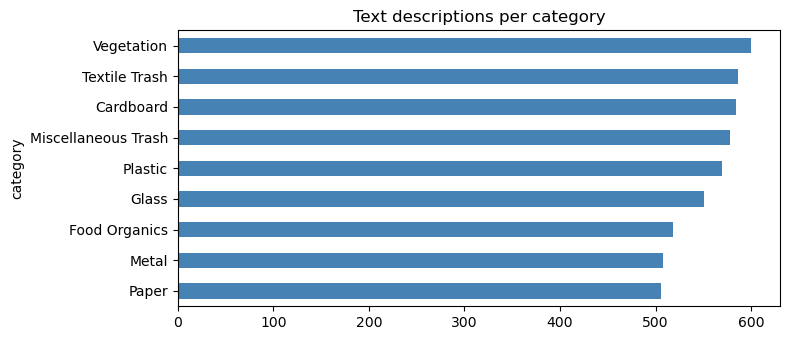


Description length (words): {'mean': 5.05, 'min': 1.0, '50%': 5.0, 'max': 12.0}
Vocabulary size: 309 unique tokens
Frequent tokens (>=20 docs): 295;  171 of them are >=95% pure to one category
Most ambiguous frequent tokens (likely colours / sizes / conditions): ['with', 'brand', 'large', 'patterned', 'ripped', 'residue', 'gold', 'standard', 'tiny', 'friendly', 'eco', 'broken']

Most frequent tokens per category:
  Cardboard            ['box', 'cardboard', 'with', 'packaging', 'sized', 'food', 'empty', 'residue']
  Food Organics        ['peel', 'food', 'with', 'shells', 'scraps', 'orange', 'empty', 'sized']
  Glass                ['glass', 'bottle', 'with', 'sized', 'residue', 'sheet', 'light', 'bulb']
  Metal                ['metal', 'can', 'with', 'sized', 'wire', 'hanger', 'bottle', 'steel']
  Miscellaneous Trash  ['with', 'sized', 'vacuum', 'disposable', 'plastic', 'rubber', 'ceramic', 'composite']
  Paper                ['paper', 'with', 'notebook', 'sized', 'residue', 'paperback

In [ ]:
# 1.2  Load and explore the waste description text data
TEXT_CSV = 'waste_descriptions.csv'
df_text = pd.read_csv(TEXT_CSV)
print("shape:", df_text.shape)
print(df_text.head().to_string(), "\n")
print("missing values per column:\n", df_text.isna().sum().to_string(), "\n")

# --- Distribution of categories --------------------------------------------------------------
cat_counts = df_text['category'].value_counts()
print(cat_counts.to_string())
CATEGORIES = sorted(df_text['category'].unique())
fig, ax = plt.subplots(figsize=(8, 3.5))
cat_counts.sort_values().plot.barh(ax=ax, color='steelblue'); ax.set_title('Text descriptions per category')
plt.tight_layout(); plt.show()

# --- Vocabulary and structure -----------------------------------------------------------------
tok = lambda s: re.findall(r"[a-z0-9]+", str(s).lower())
df_text['n_words'] = df_text['description'].map(lambda s: len(tok(s)))
vocab = collections.Counter(w for s in df_text['description'] for w in tok(s))
print(f"\nDescription length (words): {df_text['n_words'].describe()[['mean','min','50%','max']].round(2).to_dict()}")
print(f"Vocabulary size: {len(vocab)} unique tokens")

# Are tokens category-specific?  'purity' = share of a token's occurrences that fall in its top category.
tok_cat = collections.defaultdict(collections.Counter)
for s, c in zip(df_text['description'], df_text['category']):
    for w in set(tok(s)): tok_cat[w][c] += 1
purity = {w: max(cnt.values()) / sum(cnt.values()) for w, cnt in tok_cat.items() if sum(cnt.values()) >= 20}
print(f"Frequent tokens (>=20 docs): {len(purity)};  {sum(v >= 0.95 for v in purity.values())} of them are >=95% pure to one category")
print("Most ambiguous frequent tokens (likely colours / sizes / conditions):",
      sorted(purity, key=purity.get)[:12])

print("\nMost frequent tokens per category:")
for c in CATEGORIES:
    cnt = collections.Counter(w for s in df_text.loc[df_text.category == c, 'description'] for w in tok(s))
    print(f"  {c:20s}", [w for w, _ in cnt.most_common(8)])

# --- Auxiliary columns ------------------------------------------------------------------------
print("\nUnique disposal_instruction values per category:", df_text.groupby('category')['disposal_instruction'].nunique().unique())
print("common_confusion filled for", f"{df_text['common_confusion'].notna().mean():.0%}", "of rows; unique values:", df_text['common_confusion'].nunique())
print("material_composition unique values:", df_text['material_composition'].nunique(), "(one per category)")

# --- Duplicates and label noise ----------------------------------------------------------------
dup = df_text.duplicated('description', keep=False)
conflict = df_text[dup].groupby('description')['category'].nunique()
print(f"\nRows sharing a description with another row: {dup.sum()};  descriptions with conflicting labels: {(conflict > 1).sum()}")

In [ ]:
# 1.2  Load and explore the waste policy documents
# NOTE: the starter comment says .csv, but the policy file supplied is waste_policy_documents.json.
with open('waste_policy_documents.json') as f:
    policy_docs = json.load(f)
df_policy = pd.DataFrame(policy_docs)
df_policy['n_categories'] = df_policy['categories_covered'].map(len)
df_policy['n_words'] = df_policy['document_text'].map(lambda s: len(s.split()))
print(df_policy[['policy_id', 'policy_type', 'categories_covered', 'effective_date', 'n_words']].to_string(index=False))

def split_sections(doc_text):
    """Split a policy document into (header, [items]) pairs. Headers are lines that end with ':'"""
    sections, current, buf = [], None, []
    for line in doc_text.split('\n'):
        s = line.strip()
        if not s: continue
        m = re.match(r'^([A-Za-z][A-Za-z \-/]+):$', s)
        if m:
            if current is not None: sections.append((current, buf))
            current, buf = m.group(1).strip(), []
        elif current is not None:          # the first (title) line before any header is skipped
            buf.append(s.lstrip('-').strip())
    if current is not None: sections.append((current, buf))
    return sections

def section_category(header, doc):
    """Which waste category does a section describe?  (combined docs name it in the header)"""
    h = header.lower()
    for c in CATEGORIES:
        if c.lower() in h: return c
    return doc['categories_covered'][0] if len(doc['categories_covered']) == 1 else 'General'

print("\nDocument organisation:")
print(" - dedicated single-category policies:", int((df_policy.n_categories == 1).sum()),
      "| combined multi-category policies:", int((df_policy.n_categories > 1).sum()))
print(" - section headers used:", sorted({h for d in policy_docs for h, _ in split_sections(d['document_text'])}))
print(" - jurisdictions:", df_policy.jurisdiction.unique().tolist(), "| dates:", df_policy.effective_date.min(), "to", df_policy.effective_date.max())

# Do the combined documents agree with the dedicated ones?  The dedicated policies have explicit
# 'Non-Acceptable' sections; combined documents only list items under '<CATEGORY> GUIDELINES' headings.
not_ok = {}
for d in policy_docs:
    if len(d['categories_covered']) == 1:
        for h, items in split_sections(d['document_text']):
            if 'non-acceptable' in h.lower():      # (the Misc. Trash doc has no accept/reject split, so it is skipped)
                not_ok[d['categories_covered'][0]] = {i.lower() for i in items}
print("\nPotential policy conflicts (item listed in a combined doc but excluded by the dedicated policy):")
for d in policy_docs:
    if len(d['categories_covered']) > 1:
        for h, items in split_sections(d['document_text']):
            cat = section_category(h, d)
            for i in items:
                if i.lower() in not_ok.get(cat, set()):
                    print(f"  policy {d['policy_id']:>2} ({d['effective_date']}) {d['policy_type']}: '{i}' under {cat}")

 policy_id                              policy_type                                       categories_covered effective_date  n_words
         1       Textile Trash Recycling Guidelines                                          [Textile Trash]     2023-11-04      104
         2               Glass Recycling Guidelines                                                  [Glass]     2023-01-24       86
         3       Food Organics Recycling Guidelines                                          [Food Organics]     2023-05-08       98
         4             Plastic Recycling Guidelines                                                [Plastic]     2023-04-05       94
         5          Vegetation Recycling Guidelines                                             [Vegetation]     2023-12-04       94
         6           Cardboard Recycling Guidelines                                              [Cardboard]     2023-11-24       87
         7               Metal Recycling Guidelines                  

### 1.3 Create Data Pipelines

In [ ]:
# 1.3  Image pipeline: STRATIFIED 70 / 15 / 15 split of the file list (fixed seed), then tf.data pipelines.
# (The provided image_dataset_from_directory + validation_split + take/skip code is replaced - see the note below.)
data_dir = DATA_DIR
SEED = 42
BATCH_SIZE = 32
IMG_HEIGHT = 224
IMG_WIDTH = 224
AUTOTUNE = tf.data.AUTOTUNE

class_names = sorted(d.name for d in data_dir.iterdir() if d.is_dir() and not d.name.startswith('.'))
num_classes = len(class_names)
class_to_idx = {c: i for i, c in enumerate(class_names)}
print(f"Number of classes: {num_classes}\nClass names: {class_names}")

img_df = pd.DataFrame([(str(p), c) for c in class_names for p in sorted((data_dir / c).iterdir()) if p.suffix.lower() in IMG_EXTS],
                      columns=['path', 'label'])
print(f"Total images found: {len(img_df)}")

train_df, temp_df = train_test_split(img_df, test_size=0.30, stratify=img_df.label, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

def _load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_HEIGHT, IMG_WIDTH))                   # uniform size
    return tf.cast(tf.round(img), tf.uint8), label                        # uint8 keeps the in-memory cache 4x smaller

def make_image_ds(df, training):
    labels = tf.keras.utils.to_categorical(df.label.map(class_to_idx).values, num_classes)
    ds = tf.data.Dataset.from_tensor_slices((df.path.values, labels))
    ds = ds.map(_load_image, num_parallel_calls=AUTOTUNE).cache()
    if training: ds = ds.shuffle(2048, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)   # model expects float 0-255
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_image_ds(train_df, training=True)
validation_ds = make_image_ds(val_df, training=False)
test_dataset = make_image_ds(test_df, training=False)    # never shuffled -> prediction order == test_df order
print(f"Batches - train {len(train_ds)} | validation {len(validation_ds)} | test {len(test_dataset)}")

Number of classes: 9
Class names: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Total images found: 4752
Batches - train 104 | validation 23 | test 23


**Why the provided split was replaced (this was a real bug, not a style choice).**

1. In `image_dataset_from_directory`, `validation_split` only shuffles the file list when `shuffle=True`. The "un-shuffled copy" used to rebuild the hold-out therefore returned the **last 20 % of the files in alphabetical order** - i.e. only *Plastic, Textile Trash and Vegetation*. The test set contained 0 images of the other six classes (accuracy 0.946 but macro-F1 0.36).
2. The training subset (`shuffle=True`) and that hold-out were cut from *different orderings* of the files, so they were **not complementary**: many "test" images were also training images (data leakage), which inflated validation/test accuracy.
3. `take()`/`skip()` on a shuffled dataset can additionally mix the validation and test halves.

The fix is to split the **file list once**, **stratified by class**, with a fixed seed (70 % train / 15 % validation / 15 % test), and build the `tf.data` pipelines from those lists. Every class appears in every split and the three sets are disjoint (checked in the next cell).

In [ ]:
# Sanity checks: disjoint splits, every class present in every split, proportions preserved
assert not (set(train_df.path) & set(val_df.path)) and not (set(train_df.path) & set(test_df.path)) and not (set(val_df.path) & set(test_df.path)), 'splits overlap!'
split_counts = pd.DataFrame({'train': train_df.label.value_counts(), 'val': val_df.label.value_counts(), 'test': test_df.label.value_counts()}).reindex(class_names)
assert split_counts.notna().all().all(), 'a class is missing from a split'
print(split_counts.to_string()); print('\nTotals:', split_counts.sum().to_dict())

                     train  val  test
label                                
Cardboard              323   69    69
Food Organics          288   61    62
Glass                  294   63    63
Metal                  553  119   118
Miscellaneous Trash    346   74    75
Paper                  350   75    75
Plastic                645  138   138
Textile Trash          222   48    48
Vegetation             305   66    65

Totals: {'train': 3326, 'val': 713, 'test': 713}


In [ ]:
# 1.3  Text preprocessing pipeline for the classifier
# Steps: (1) normalise text  (2) tokenise  (3) de-duplicate / remove label-conflicting rows
#        (4) stratified train / validation / test split  (5) TF-IDF features (fit on TRAIN only)

def clean_text(t):
    """Lower-case, strip punctuation/symbols, collapse whitespace."""
    t = str(t).lower()
    t = re.sub(r"[^a-z0-9\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def tokenize(t):
    return clean_text(t).split()

df_clean = df_text[['description', 'category']].copy()
df_clean['clean'] = df_clean['description'].map(clean_text)

# Identical descriptions in two splits would leak the answer, so keep one copy of each; drop any with conflicting labels.
n_labels = df_clean.groupby('clean')['category'].nunique()
conflicting = set(n_labels[n_labels > 1].index)
df_clean = df_clean[~df_clean['clean'].isin(conflicting)].drop_duplicates('clean').reset_index(drop=True)
print(f"rows: {len(df_text)} -> {len(df_clean)} after removing duplicates and {len(conflicting)} label-conflicting descriptions")

# 70 / 15 / 15 stratified split
X_trainval, X_test, y_trainval, y_test = train_test_split(
    df_clean['clean'], df_clean['category'], test_size=0.15, stratify=df_clean['category'], random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15 / 0.85, stratify=y_trainval, random_state=42)
print(f"train {len(X_train)} | validation {len(X_val)} | test {len(X_test)}")

# Sparse features: uni+bi-grams, sub-linear TF.  Fit on the training split only (no leakage).
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
Xtr_tfidf = tfidf.fit_transform(X_train)
print("TF-IDF feature matrix:", Xtr_tfidf.shape)
print("example:", df_text.description[0], '->', tokenize(df_text.description[0]))

rows: 5000 -> 4939 after removing duplicates and 0 label-conflicting descriptions
train 3457 | validation 741 | test 741
TF-IDF feature matrix: (3457, 4979)
example: soiled silver tablecloth -> ['soiled', 'silver', 'tablecloth']


In [ ]:
# 1.3  Prepare documents for RAG: parse policies into section-level chunks
# Chunks come from two sources:  (a) the policy documents, (b) the per-category disposal instructions and
# 'common confusion' notes in waste_descriptions.csv (the lab asks us to use both).
# Section-level chunking keeps each chunk about ONE category and ONE topic, so retrieval can be precise.

chunks = []
for doc in policy_docs:
    dedicated = len(doc['categories_covered']) == 1
    for header, items in split_sections(doc['document_text']):
        cat = section_category(header, doc)
        chunks.append(dict(source='policy', policy_id=doc['policy_id'], policy_type=doc['policy_type'],
                           effective_date=doc['effective_date'], dedicated=dedicated,
                           category=cat, section=header, text='; '.join(items)))
for cat, g in df_text.groupby('category'):
    for tip in g['disposal_instruction'].dropna().unique():
        chunks.append(dict(source='disposal_instruction', policy_id=None, policy_type='Disposal instruction (CSV)',
                           effective_date=None, dedicated=False, category=cat, section='Disposal tip', text=tip))
    for conf in g['common_confusion'].dropna().unique():
        chunks.append(dict(source='common_confusion', policy_id=None, policy_type='Common confusion (CSV)',
                           effective_date=None, dedicated=False, category=cat, section='Common confusion', text=conf))
for i, c in enumerate(chunks):
    c['chunk_id'] = i
    c['embed_text'] = f"{c['category']} | {c['section']}: {c['text']}"      # category in the text helps retrieval
print(f"{len(chunks)} chunks:", collections.Counter(c['source'] for c in chunks))

# --- Embedding model ----------------------------------------------------------------------------
# Preferred: a pre-trained sentence-embedding model.  Fallback (e.g. no internet): TF-IDF vectors with the
# same .encode() interface, so every downstream cell works either way.
class TfidfEmbedder:
    def __init__(self, corpus):
        self.v = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(corpus)
    def encode(self, texts, normalize_embeddings=True, **kw):
        return self.v.transform(list(texts)).toarray().astype(np.float32)   # rows are already L2-normalised

try:
    from sentence_transformers import SentenceTransformer
    embedder = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
    USING_SBERT = True
except Exception as e:
    print("sentence-transformers unavailable -> falling back to TF-IDF embeddings:", type(e).__name__)
    embedder = TfidfEmbedder([c['embed_text'] for c in chunks] + list(X_train))
    USING_SBERT = False
chunk_emb = embedder.encode([c['embed_text'] for c in chunks], normalize_embeddings=True)
print("embedding model:", 'all-MiniLM-L6-v2' if USING_SBERT else 'TF-IDF fallback', "| chunk embedding matrix:", chunk_emb.shape)

121 chunks: Counter({'policy': 67, 'disposal_instruction': 45, 'common_confusion': 9})


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embedding model: all-MiniLM-L6-v2 | chunk embedding matrix: (121, 384)


## Part 2: Waste Material Classification with CNN

In this section, you will build a CNN model to classify waste materials from images.

### 2.1 Preprocess Images

In [ ]:
# 2.1  Image preprocessing
# The pipeline from 1.3 already resizes every image to 224x224 and batches it.  Two more steps are applied
# INSIDE the model (so they travel with it when it is saved and are applied identically at inference time):
#   * normalisation: MobileNetV2 expects pixels in [-1, 1]  ->  x / 127.5 - 1
#   * augmentation (training only): flips, small rotations / zooms / contrast changes.  Waste items can appear in any
#     orientation, and RealWaste has only a few thousand images, so augmentation is the cheapest regulariser.
normalize = layers.Rescaling(1. / 127.5, offset=-1, name='normalize')
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name='augmentation')

# Map the image-folder names ('1-Cardboard', ...) to the category strings used by the text data and policies.
def folder_to_category(name):
    return re.sub(r'^\d+[-_ ]*', '', name).strip()
IMG_CLASS_TO_CATEGORY = {c: folder_to_category(c) for c in class_names}
print(IMG_CLASS_TO_CATEGORY)
missing = set(IMG_CLASS_TO_CATEGORY.values()) - set(CATEGORIES)
print("image classes without a matching text category:", missing or "none")

# Class imbalance: compute balanced class weights from the training labels
train_labels = train_df.label.map(class_to_idx).values
cw = compute_class_weight('balanced', classes=np.arange(num_classes), y=train_labels)
class_weight = {i: float(w) for i, w in enumerate(cw)}
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

{'Cardboard': 'Cardboard', 'Food Organics': 'Food Organics', 'Glass': 'Glass', 'Metal': 'Metal', 'Miscellaneous Trash': 'Miscellaneous Trash', 'Paper': 'Paper', 'Plastic': 'Plastic', 'Textile Trash': 'Textile Trash', 'Vegetation': 'Vegetation'}
image classes without a matching text category: none
{'Cardboard': 1.14, 'Food Organics': 1.28, 'Glass': 1.26, 'Metal': 0.67, 'Miscellaneous Trash': 1.07, 'Paper': 1.06, 'Plastic': 0.57, 'Textile Trash': 1.66, 'Vegetation': 1.21}


### 2.2 Implement CNN Model with Transfer Learning

In [ ]:
# 2.2  CNN with transfer learning
# Base model: MobileNetV2 pre-trained on ImageNet.  Why: only a few thousand training images, so re-using ImageNet features
# is far better than training from scratch; MobileNetV2 is small (2.3M params) and fast enough to train on a free Colab GPU
# and to serve for a city-wide app.  Stage 1 freezes the base and trains only the new classification head.

def build_model(units=256, dropout=0.4, l2=1e-4, lr=1e-3):
    base = keras.applications.MobileNetV2(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3), include_top=False, weights='imagenet')
    base.trainable = False
    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = data_augmentation(inputs)                      # active only when training=True
    x = normalize(x)
    x = base(x, training=False)                        # keep BatchNorm statistics frozen
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(units, activation='relu', kernel_regularizer=keras.regularizers.l2(l2))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)   # one output per waste category
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='categorical_crossentropy',            # labels are one-hot (label_mode='categorical')
                  metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=2, name='top2_acc')])
    return model

def get_base(model):
    return [l for l in model.layers if isinstance(l, keras.Model)][0]

baseline_cfg = dict(units=256, dropout=0.4, l2=1e-4, lr=1e-3)
cnn = build_model(**baseline_cfg)
cnn.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalize (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,353 (9.89 MB)

 Trainable params: 332,809 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

### 2.3 Train and Evaluate the Model

Epoch 1/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 178s 1s/step - accuracy: 0.4994 - loss: 1.7148 - top2_acc: 0.6810 - val_accuracy: 0.6999 - val_loss: 0.9328 - val_top2_acc: 0.8485 - learning_rate: 0.0010
Epoch 2/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 166s 1s/step - accuracy: 0.6548 - loss: 1.0796 - top2_acc: 0.8331 - val_accuracy: 0.7560 - val_loss: 0.7865 - val_top2_acc: 0.8920 - learning_rate: 0.0010
Epoch 3/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.6960 - loss: 0.9207 - top2_acc: 0.8608 - val_accuracy: 0.7588 - val_loss: 0.7607 - val_top2_acc: 0.9046 - learning_rate: 0.0010
Epoch 4/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 124s 1s/step - accuracy: 0.7120 - loss: 0.8566 - top2_acc: 0.8770 - val_accuracy: 0.7714 - val_loss: 0.7502 - val_top2_acc: 0.9074 - learning_rate: 0.0010
Epoch 5/15
104/104 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.7357 - loss: 0.7967 - top2_acc: 0.8867 - val_accuracy: 0.7574 - val_loss: 0.8153 - val_top2_acc: 0.9046 - learning_rate: 0.0010
Epoch 6/15
104/104 ━━━━━━

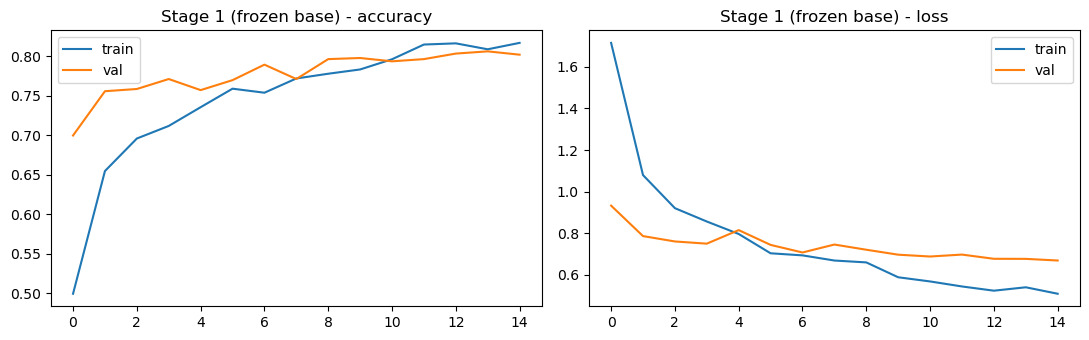

In [ ]:
# 2.3  Train the CNN (stage 1: frozen base)
# Regularisation: dropout (x2), L2 on the dense layer, data augmentation, class weights, EarlyStopping with
# best-weights restore, and ReduceLROnPlateau.  Batch size is 32 (set in the pipeline).
def make_callbacks(patience=4):
    return [keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-6)]

def plot_history(histories, title):
    h = {}
    for hist in histories:
        for k, v in hist.history.items(): h.setdefault(k, []).extend(v)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h['accuracy'], label='train'); ax[0].plot(h['val_accuracy'], label='val'); ax[0].set_title(title + ' - accuracy'); ax[0].legend()
    ax[1].plot(h['loss'], label='train'); ax[1].plot(h['val_loss'], label='val'); ax[1].set_title(title + ' - loss'); ax[1].legend()
    plt.tight_layout(); plt.show()

hist_stage1 = cnn.fit(train_ds, validation_data=validation_ds, epochs=15,
                      class_weight=class_weight, callbacks=make_callbacks())
plot_history([hist_stage1], 'Stage 1 (frozen base)')
# Reading the curves: a widening gap between train and validation accuracy means over-fitting;
# validation accuracy above training accuracy early on is normal here (dropout + augmentation only act on the training pass).

Stage 1 CNN: accuracy = 0.8149  |  macro-F1 = 0.8203
                     precision    recall  f1-score   support

          Cardboard      0.806     0.841     0.823        69
      Food Organics      0.944     0.823     0.879        62
              Glass      0.681     0.778     0.726        63
              Metal      0.831     0.831     0.831       118
Miscellaneous Trash      0.783     0.627     0.696        75
              Paper      0.819     0.907     0.861        75
            Plastic      0.818     0.717     0.764       138
      Textile Trash      0.825     0.979     0.895        48
         Vegetation      0.842     0.985     0.908        65

           accuracy                          0.815       713
          macro avg      0.817     0.832     0.820       713
       weighted avg      0.817     0.815     0.812       713



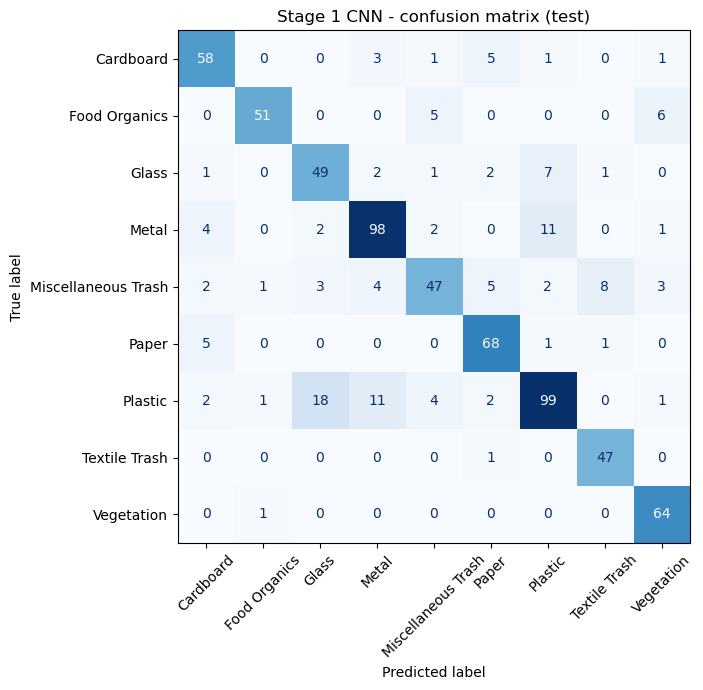

Most frequent confusions (count, true -> predicted):
   18  Plastic  ->  Glass
   11  Plastic  ->  Metal
   11  Metal  ->  Plastic
    8  Miscellaneous Trash  ->  Textile Trash
    7  Glass  ->  Plastic
    6  Food Organics  ->  Vegetation
    5  Paper  ->  Cardboard
    5  Miscellaneous Trash  ->  Paper

Per-class recall (hardest first): [('Miscellaneous Trash', 0.627), ('Plastic', 0.717), ('Glass', 0.778), ('Food Organics', 0.823)]


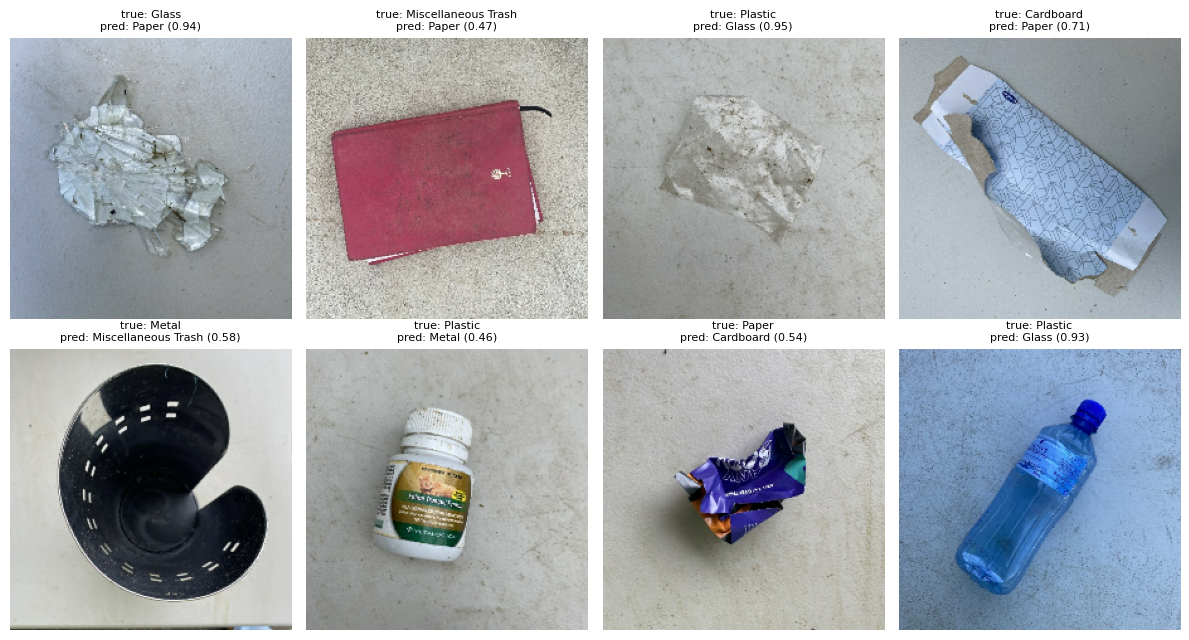

In [ ]:
# 2.3  Evaluate the CNN on the held-out test set
def predict_dataset(model, ds):
    """One pass over ds returning labels, probabilities and (uint8) images, so order always matches."""
    y_true, y_prob, imgs = [], [], []
    for x, y in ds:
        y_prob.append(model.predict(x, verbose=0)); y_true.append(np.argmax(y.numpy(), axis=1)); imgs.append(x.numpy().astype('uint8'))
    return np.concatenate(y_true), np.concatenate(y_prob), np.concatenate(imgs)

def evaluate_cnn(model, ds, title='CNN'):
    y_true, y_prob, imgs = predict_dataset(model, ds)
    y_pred = y_prob.argmax(1)
    labels = np.arange(num_classes)                       # always report all classes, even if one were missing
    acc = accuracy_score(y_true, y_pred)
    print(f"{title}: accuracy = {acc:.4f}  |  macro-F1 = {f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0):.4f}")
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(cm, display_labels=[folder_to_category(c) for c in class_names]).plot(ax=ax, xticks_rotation=45, colorbar=False, cmap='Blues')
    ax.set_title(f'{title} - confusion matrix (test)'); plt.tight_layout(); plt.show()
    return dict(y_true=y_true, y_pred=y_pred, y_prob=y_prob, imgs=imgs, acc=acc, cm=cm)

def analyse_errors(res, n_show=8):
    cm = res['cm'].copy(); np.fill_diagonal(cm, 0)
    pairs = sorted([(cm[i, j], class_names[i], class_names[j]) for i in range(num_classes) for j in range(num_classes) if cm[i, j]], reverse=True)
    print("Most frequent confusions (count, true -> predicted):")
    for n, t, p in pairs[:8]: print(f"  {n:3d}  {t}  ->  {p}")
    recall = res['cm'].diagonal() / np.maximum(res['cm'].sum(1), 1)
    print("\nPer-class recall (hardest first):", [(class_names[i], round(float(recall[i]), 3)) for i in np.argsort(recall)[:4]])
    wrong = np.where(res['y_true'] != res['y_pred'])[0][:n_show]
    if len(wrong):
        fig, axes = plt.subplots(2, (len(wrong) + 1) // 2, figsize=(3 * ((len(wrong) + 1) // 2), 6.5)); axes = np.atleast_1d(axes).ravel()
        for ax, i in zip(axes, wrong):
            ax.imshow(res['imgs'][i]); ax.axis('off')
            ax.set_title(f"true: {folder_to_category(class_names[res['y_true'][i]])}\npred: {folder_to_category(class_names[res['y_pred'][i]])} ({res['y_prob'][i].max():.2f})", fontsize=8)
        for ax in axes[len(wrong):]: ax.axis('off')
        plt.tight_layout(); plt.show()

res_base = evaluate_cnn(cnn, test_dataset, 'Stage 1 CNN')
analyse_errors(res_base)

### 2.4 Fine-tune the Model

{'units': 128, 'dropout': 0.3, 'l2': 0.0001, 'lr': 0.001} -> best val acc 0.7588
{'units': 256, 'dropout': 0.5, 'l2': 0.001, 'lr': 0.001} -> best val acc 0.7672
{'units': 512, 'dropout': 0.5, 'l2': 0.0001, 'lr': 0.0005} -> best val acc 0.7616
{'units': 256, 'dropout': 0.4, 'l2': 0.0001, 'lr': 0.0003} -> best val acc 0.7560

Best head configuration: {'units': 256, 'dropout': 0.5, 'l2': 0.001, 'lr': 0.001}
Epoch 1/15
104/104 - 131s - 1s/step - accuracy: 0.4597 - loss: 2.4304 - top2_acc: 0.6404 - val_accuracy: 0.7111 - val_loss: 1.2902 - val_top2_acc: 0.8808 - learning_rate: 0.0010
Epoch 2/15
104/104 - 132s - 1s/step - accuracy: 0.6025 - loss: 1.7526 - top2_acc: 0.7925 - val_accuracy: 0.7405 - val_loss: 1.2050 - val_top2_acc: 0.8906 - learning_rate: 0.0010
Epoch 3/15
104/104 - 144s - 1s/step - accuracy: 0.6329 - loss: 1.5798 - top2_acc: 0.8145 - val_accuracy: 0.7391 - val_loss: 1.2041 - val_top2_acc: 0.8948 - learning_rate: 0.0010
Epoch 4/15
104/104 - 111s - 1s/step - accuracy: 0.6678 - l

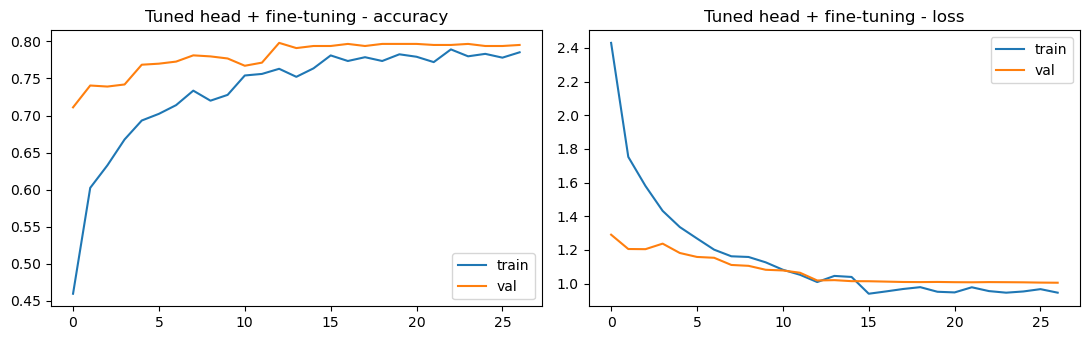

validation accuracy: {'stage-1 baseline': 0.8022, 'tuned + fine-tuned': 0.7952}
Final CNN: accuracy = 0.8149  |  macro-F1 = 0.8203
                     precision    recall  f1-score   support

          Cardboard      0.806     0.841     0.823        69
      Food Organics      0.944     0.823     0.879        62
              Glass      0.681     0.778     0.726        63
              Metal      0.831     0.831     0.831       118
Miscellaneous Trash      0.783     0.627     0.696        75
              Paper      0.819     0.907     0.861        75
            Plastic      0.818     0.717     0.764       138
      Textile Trash      0.825     0.979     0.895        48
         Vegetation      0.842     0.985     0.908        65

           accuracy                          0.815       713
          macro avg      0.817     0.832     0.820       713
       weighted avg      0.817     0.815     0.812       713



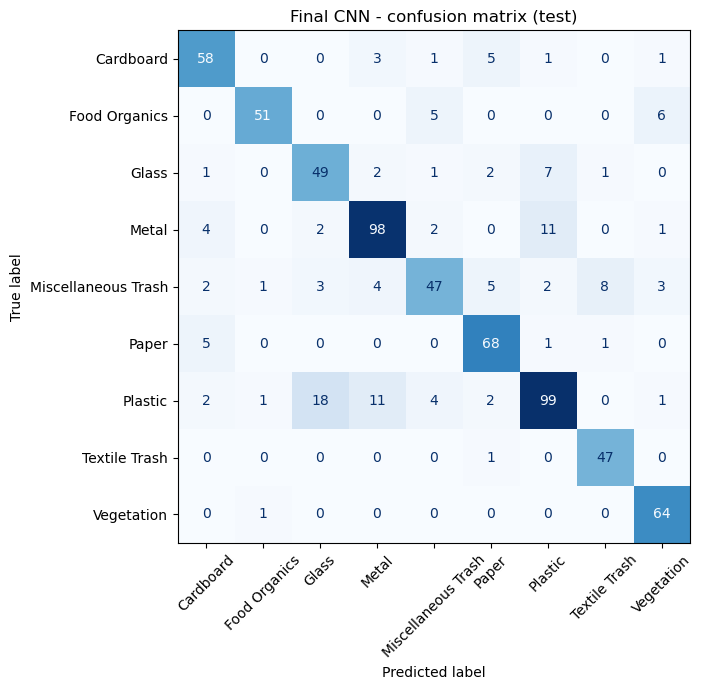

Most frequent confusions (count, true -> predicted):
   18  Plastic  ->  Glass
   11  Plastic  ->  Metal
   11  Metal  ->  Plastic
    8  Miscellaneous Trash  ->  Textile Trash
    7  Glass  ->  Plastic
    6  Food Organics  ->  Vegetation
    5  Paper  ->  Cardboard
    5  Miscellaneous Trash  ->  Paper

Per-class recall (hardest first): [('Miscellaneous Trash', 0.627), ('Plastic', 0.717), ('Glass', 0.778), ('Food Organics', 0.823)]


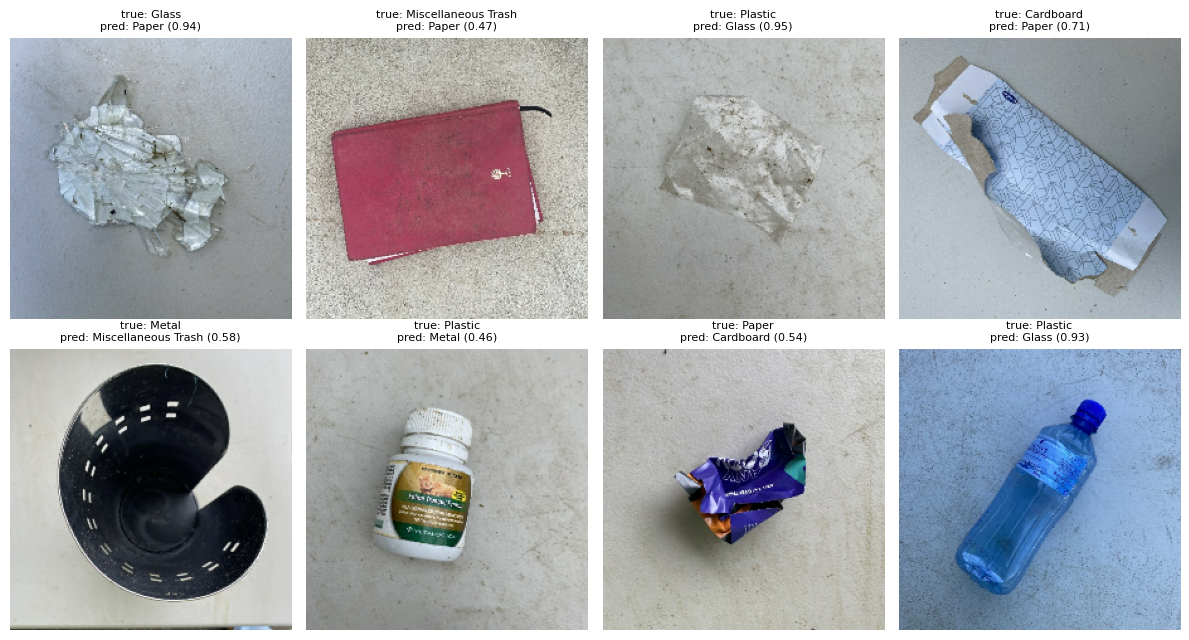

Test accuracy: baseline 0.8149  ->  final 0.8149


In [ ]:
# 2.4  Tune the CNN
# (a) Small hyper-parameter sweep on the head (depth/width via `units`, dropout, L2, learning rate) - short runs, judged on VALIDATION.
SWEEP_EPOCHS = 6
sweep = [dict(units=128, dropout=0.3, l2=1e-4, lr=1e-3),
         dict(units=256, dropout=0.5, l2=1e-3, lr=1e-3),
         dict(units=512, dropout=0.5, l2=1e-4, lr=5e-4),
         dict(units=256, dropout=0.4, l2=1e-4, lr=3e-4)]
sweep_results = []
for cfg in sweep:
    m = build_model(**cfg)
    h = m.fit(train_ds, validation_data=validation_ds, epochs=SWEEP_EPOCHS, class_weight=class_weight, verbose=0)
    sweep_results.append((max(h.history['val_accuracy']), cfg))
    print(f"{cfg} -> best val acc {sweep_results[-1][0]:.4f}")
best_cfg = max(sweep_results, key=lambda r: r[0])[1]
print("\nBest head configuration:", best_cfg)

# (b) Re-train the best head for longer
cnn_tuned = build_model(**best_cfg)
hist_tuned = cnn_tuned.fit(train_ds, validation_data=validation_ds, epochs=15, class_weight=class_weight, callbacks=make_callbacks(), verbose=2)

# (c) Fine-tune: unfreeze the top 40 layers of MobileNetV2 with a very low learning rate (BatchNorm layers stay frozen).
base = get_base(cnn_tuned)
base.trainable = True
for layer in base.layers[:-40]: layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization): layer.trainable = False
cnn_tuned.compile(optimizer=keras.optimizers.Adam(1e-5), loss='categorical_crossentropy',
                  metrics=['accuracy', keras.metrics.TopKCategoricalAccuracy(k=2, name='top2_acc')])
hist_ft = cnn_tuned.fit(train_ds, validation_data=validation_ds, epochs=12, class_weight=class_weight, callbacks=make_callbacks(), verbose=2)
plot_history([hist_tuned, hist_ft], 'Tuned head + fine-tuning')

# (d) Compare on validation (choose) and test (report).  The model is picked on VALIDATION accuracy only.
val_acc = {name: m.evaluate(validation_ds, verbose=0)[1] for name, m in [('stage-1 baseline', cnn), ('tuned + fine-tuned', cnn_tuned)]}
print("validation accuracy:", {k: round(v, 4) for k, v in val_acc.items()})
best_model = cnn_tuned if val_acc['tuned + fine-tuned'] >= val_acc['stage-1 baseline'] else cnn
best_model.save('best_cnn.keras')
res_final = evaluate_cnn(best_model, test_dataset, 'Final CNN')
analyse_errors(res_final)
print(f"Test accuracy: baseline {res_base['acc']:.4f}  ->  final {res_final['acc']:.4f}")

## Part 3: Waste Description Classification

In this section, you will build a text classification model to categorize waste based on descriptions.

### 3.1 Preprocess Text Data

In [ ]:
# 3.1  Apply the text preprocessing pipeline: transform every split with the TRAIN-fitted TF-IDF vectoriser
Xva_tfidf = tfidf.transform(X_val)
Xte_tfidf = tfidf.transform(X_test)
print("train / val / test feature shapes:", Xtr_tfidf.shape, Xva_tfidf.shape, Xte_tfidf.shape)

# Dense, pre-trained sentence embeddings as a second representation (only when sentence-transformers is available).
if USING_SBERT:
    Etr, Eva, Ete = (embedder.encode(list(s), normalize_embeddings=True) for s in (X_train, X_val, X_test))
    print("sentence-embedding shapes:", Etr.shape, Eva.shape, Ete.shape)
else:
    print("Dense embeddings skipped (sentence-transformers not installed); TF-IDF features are used.")

train / val / test feature shapes: (3457, 4979) (741, 4979) (741, 4979)
sentence-embedding shapes: (3457, 384) (741, 384) (741, 384)


### 3.2 Implement Text Classification Model

In [ ]:
# 3.2  Text classification model  ->  Option A (traditional ML on TF-IDF features, plus a dense-embedding variant)
# Why Option A?  Descriptions are short (about 5 words) and keyword-driven, so a linear model on word/bigram features is
# expected to do about as well as a fine-tuned transformer, trains in seconds, is easy to inspect and cheap to serve.
candidates = {
    'Naive Bayes (TF-IDF)':        (MultinomialNB(alpha=0.1), 'tfidf'),
    'Logistic Regression (TF-IDF)': (LogisticRegression(C=10, max_iter=2000), 'tfidf'),
    'Random Forest (TF-IDF)':      (RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1), 'tfidf'),
}
if USING_SBERT:
    candidates['Logistic Regression (MiniLM embeddings)'] = (LogisticRegression(C=10, max_iter=2000), 'dense')
feats = {'tfidf': (Xtr_tfidf, Xva_tfidf, Xte_tfidf)}
if USING_SBERT: feats['dense'] = (Etr, Eva, Ete)
print(list(candidates))

['Naive Bayes (TF-IDF)', 'Logistic Regression (TF-IDF)', 'Random Forest (TF-IDF)', 'Logistic Regression (MiniLM embeddings)']


### 3.3 Train and Evaluate the Model

In [ ]:
# 3.3  Train the candidates; choose on VALIDATION performance
fit_results = {}
for name, (clf, ft) in candidates.items():
    t0 = time.time(); clf.fit(feats[ft][0], y_train)
    pred = clf.predict(feats[ft][1])
    fit_results[name] = dict(val_acc=accuracy_score(y_val, pred), val_f1=f1_score(y_val, pred, average='macro'), secs=time.time() - t0)
print(pd.DataFrame(fit_results).T.round(4).to_string())

# Small regularisation search for logistic regression (validation accuracy), then 5-fold CV on train+val as a stability check.
best_C, best_va = None, -1
for Cval in [0.1, 1, 10, 100]:
    va = accuracy_score(y_val, LogisticRegression(C=Cval, max_iter=2000).fit(Xtr_tfidf, y_train).predict(Xva_tfidf))
    print(f"LogReg C={Cval:<6} val acc {va:.4f}")
    if va > best_va: best_C, best_va = Cval, va

best_name = max(fit_results, key=lambda n: (fit_results[n]['val_acc'], fit_results[n]['val_f1']))
print("\nSelected model:", best_name)
cv = cross_val_score(LogisticRegression(C=best_C, max_iter=2000), tfidf.transform(pd.concat([X_train, X_val])),
                     pd.concat([y_train, y_val]), cv=StratifiedKFold(5, shuffle=True, random_state=42))
print(f"5-fold CV accuracy (LogReg C={best_C}): {cv.mean():.4f} +/- {cv.std():.4f}")

# Final deployed text model: TF-IDF + logistic regression (gives calibrated-ish probabilities for the confidence score).
text_clf = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
                     ('clf', LogisticRegression(C=best_C, max_iter=2000))]).fit(X_train, y_train)

                                         val_acc  val_f1    secs
Naive Bayes (TF-IDF)                      0.9838  0.9842  0.0770
Logistic Regression (TF-IDF)              0.9973  0.9974  0.4989
Random Forest (TF-IDF)                    0.9825  0.9826  4.0116
Logistic Regression (MiniLM embeddings)   0.9919  0.9920  0.4155
LogReg C=0.1    val acc 0.9730
LogReg C=1      val acc 0.9946
LogReg C=10     val acc 0.9973
LogReg C=100    val acc 0.9987

Selected model: Logistic Regression (TF-IDF)
5-fold CV accuracy (LogReg C=100): 0.9995 +/- 0.0006


Test accuracy: 0.9973 | macro-F1: 0.9973
                     precision    recall  f1-score   support

          Cardboard      1.000     1.000     1.000        87
      Food Organics      1.000     1.000     1.000        77
              Glass      0.988     1.000     0.994        81
              Metal      1.000     1.000     1.000        76
Miscellaneous Trash      1.000     0.977     0.988        87
              Paper      0.987     1.000     0.993        74
            Plastic      1.000     1.000     1.000        83
      Textile Trash      1.000     1.000     1.000        88
         Vegetation      1.000     1.000     1.000        88

           accuracy                          0.997       741
          macro avg      0.997     0.997     0.997       741
       weighted avg      0.997     0.997     0.997       741



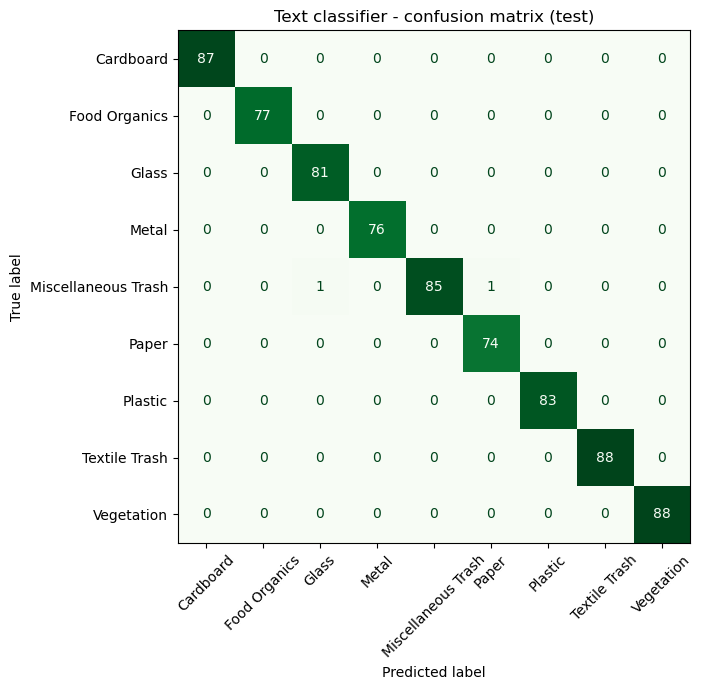


2 misclassified of 741:
                description                true  pred  confidence
              red glass pen Miscellaneous Trash Glass    0.527048
partial purple paper marker Miscellaneous Trash Paper    0.659742

Out-of-template descriptions (prediction, confidence):
  greasy pizza box                 -> Cardboard            1.00
  empty pringles tube              -> Cardboard            0.51
  old t-shirt with a hole          -> Textile Trash        1.00
  broken ceramic mug               -> Miscellaneous Trash  1.00
  dead AA batteries                -> Textile Trash        0.21
  banana peel                      -> Food Organics        1.00
  wine bottle                      -> Glass                1.00
  crushed soda can                 -> Metal                1.00
  prunings from my apple tree      -> Vegetation           0.84
  styrofoam takeaway tray          -> Miscellaneous Trash  0.99
  plastic bag full of leaves       -> Plastic              0.96
  metal jar lid  

In [ ]:
# 3.3  Evaluate on the held-out TEST set
y_pred_text = text_clf.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_text):.4f} | macro-F1: {f1_score(y_test, y_pred_text, average='macro'):.4f}")
print(classification_report(y_test, y_pred_text, digits=3))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_text, labels=CATEGORIES), display_labels=CATEGORIES).plot(
    ax=ax, xticks_rotation=45, colorbar=False, cmap='Greens')
ax.set_title('Text classifier - confusion matrix (test)'); plt.tight_layout(); plt.show()

# --- Error analysis ----------------------------------------------------------------------------
errors = pd.DataFrame({'description': X_test.values, 'true': y_test.values, 'pred': y_pred_text,
                       'confidence': text_clf.predict_proba(X_test).max(1)})
errors = errors[errors.true != errors.pred]
print(f"\n{len(errors)} misclassified of {len(X_test)}:"); print(errors.to_string(index=False))

# --- Robustness check: the data is template-generated, so also try phrasings it never contains ---------
hard = ["greasy pizza box", "empty pringles tube", "old t-shirt with a hole", "broken ceramic mug", "dead AA batteries",
        "banana peel", "wine bottle", "crushed soda can", "prunings from my apple tree", "styrofoam takeaway tray",
        "plastic bag full of leaves", "metal jar lid", "glass window pane"]
probs = text_clf.predict_proba([clean_text(h) for h in hard])
print("\nOut-of-template descriptions (prediction, confidence):")
for h, p in zip(hard, probs): print(f"  {h:32s} -> {text_clf.classes_[p.argmax()]:20s} {p.max():.2f}")

### 3.4 Create Classification Function

In [ ]:
def classify_waste_description(description):
    """
    Classifies a waste description into an appropriate category.

    Args:
        description (str): Text description of waste item

    Returns:
        str: Predicted waste category
    """
    return str(text_clf.predict([clean_text(description)])[0])

def classify_waste_description_with_confidence(description, top_n=3):
    """Same as above but also returns the confidence and the top-n alternatives (used by the integrated assistant)."""
    p = text_clf.predict_proba([clean_text(description)])[0]
    order = np.argsort(p)[::-1][:top_n]
    return str(text_clf.classes_[order[0]]), float(p[order[0]]), [(str(text_clf.classes_[i]), float(p[i])) for i in order]

for q in ["crumpled newspaper", "rusty tin can", "soiled cotton tablecloth", "empty glass jar with lid"]:
    print(f"{q!r:30} -> {classify_waste_description(q)}")

'crumpled newspaper'           -> Paper
'rusty tin can'                -> Metal
'soiled cotton tablecloth'     -> Textile Trash
'empty glass jar with lid'     -> Glass


## Part 4: Recycling Instruction Generation with RAG

In this section, you will implement a Retrieval-Augmented Generation (RAG) system to generate recycling instructions.

### 4.1 Preprocess Documents for Retrieval

In [ ]:
# 4.1  Build the retrieval index and retrieval functions
# Index = the chunk-embedding matrix built in 1.3 (L2-normalised, so a dot product is cosine similarity).
# A matrix + numpy is plenty for ~100 chunks; swap in FAISS if the policy corpus grows to many thousands.
DEDICATED_BONUS = 0.10     # dedicated single-category policies outrank combined ones (see conflict note in 1.2)

def _scores(query):
    q = embedder.encode([query], normalize_embeddings=True)[0]
    return chunk_emb @ q

def retrieve_policy(query, category=None, k_docs=3):
    """Rank policy DOCUMENTS for a query. If a category is given, only documents covering it are eligible."""
    s = _scores(query); best = {}
    for c, sc in zip(chunks, s):
        if c['source'] != 'policy': continue
        if category and c['category'] not in (category, 'General'): continue
        sc = float(sc) + (DEDICATED_BONUS if c['dedicated'] else 0.0)
        best[c['policy_id']] = max(best.get(c['policy_id'], -1.0), sc)
    return sorted(best.items(), key=lambda kv: -kv[1])[:k_docs]

policy_by_id = {d['policy_id']: d for d in policy_docs}
DEDICATED_DOC = {d['categories_covered'][0]: d['policy_id'] for d in policy_docs if len(d['categories_covered']) == 1}
def doc_meta(pid):
    d = policy_by_id[pid]
    return dict(policy_id=pid, policy_type=d['policy_type'], effective_date=d['effective_date'],
                categories_covered=d['categories_covered'], jurisdiction=d['jurisdiction'])

def build_context(category, query, tip=None):
    """Assemble the text the generator is allowed to rely on:
         primary policy document (sections about this category) + the best-matching disposal tip + the common-confusion note."""
    ranked = retrieve_policy(query, category)
    primary = DEDICATED_DOC.get(category, ranked[0][0])          # the dedicated policy is authoritative (see conflict note in 1.2)
    ranked = [(primary, dict(ranked).get(primary, 1.0))] + [r for r in ranked if r[0] != primary]
    d = policy_by_id[primary]
    parts = [f"Policy: {d['policy_type']} ({d['jurisdiction']}, effective {d['effective_date']})."]
    for c in chunks:
        if c['source'] == 'policy' and c['policy_id'] == primary and c['category'] in (category, 'General') and c['section'].lower() != 'benefits':
            parts.append(f"{c['section']}: {c['text'].rstrip('.')}.")
    s = _scores(query)
    tips = [(float(s[c['chunk_id']]), c['text']) for c in chunks if c['source'] == 'disposal_instruction' and c['category'] == category]
    tip = tip or max(tips)[1]
    parts.append(f"Local tip: {tip}")
    for c in chunks:
        if c['source'] == 'common_confusion' and c['category'] == category:
            parts.append(f"Common confusion: {c['text']}"); break
    return ' '.join(parts), [doc_meta(pid) for pid, _ in ranked]

# --- quick retrieval evaluation with free-text questions (no category supplied) ---------------------------
probe = [("can I put a clean pizza box in the recycling", "Cardboard"), ("where do I take old batteries", "Miscellaneous Trash"),
         ("do grass clippings go in the yard waste bin", "Vegetation"), ("are aluminum cans accepted", "Metal"),
         ("what do I do with old clothes and towels", "Textile Trash"), ("can glass jars be recycled", "Glass"),
         ("coffee grounds and eggshells", "Food Organics"), ("newspapers and magazines", "Paper"),
         ("are PET bottles with code 1 accepted", "Plastic")]
hit1 = hit3 = 0
for q, expected in probe:
    ranked = retrieve_policy(q, k_docs=3)
    covers = [expected in policy_by_id[pid]['categories_covered'] for pid, _ in ranked]
    hit1 += covers[0]; hit3 += any(covers)
print(f"retrieval hit@1 = {hit1}/{len(probe)}   hit@3 = {hit3}/{len(probe)}   (embedding model: {'MiniLM' if USING_SBERT else 'TF-IDF fallback'})")

retrieval hit@1 = 8/9   hit@3 = 9/9   (embedding model: MiniLM)


### 4.2 Implement RAG-based System

In [ ]:
# 4.2  Generator: a pre-trained seq2seq transformer (Flan-T5) + the retrieval mechanism above
# Why Flan-T5-base (250M params)?  It is instruction-tuned (follows 'answer using the context' prompts), small enough to
# fine-tune on a free Colab GPU in minutes, and an encoder-decoder suits copy-and-condense generation from a context.
# (Use 'google/flan-t5-small' if memory is tight.)
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
GEN_MODEL = 'google/flan-t5-base'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
gen_tok = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForSeq2SeqLM.from_pretrained(GEN_MODEL).to(device)

def make_prompt(query, context):
    return f"Answer the question using only the context. Question: {query} Context: {context}"

@torch.no_grad()
def generate_text(prompts, **gen_kwargs):
    gen_model.eval()
    enc = gen_tok(prompts, return_tensors='pt', padding=True, truncation=True, max_length=512).to(device)
    out = gen_model.generate(**enc, max_new_tokens=256, **gen_kwargs)
    return gen_tok.batch_decode(out, skip_special_tokens=True)

# Zero-shot baseline (before fine-tuning) so the benefit of 4.3 is visible
for cat in ['Glass', 'Textile Trash']:
    q = f"How to recycle {cat}"
    ctx, _ = build_context(cat, q)
    print(f"--- zero-shot | {q}\n{generate_text([make_prompt(q, ctx)], num_beams=4)[0]}\n")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

--- zero-shot | How to recycle Glass
Place in dedicated glass recycling bins. Some areas require color sorting. Preparation Instructions: Rinse containers; Remove caps and lids (recycle separately); Labels can remain. Local tip: Place in glass recycling bin, sorted by color if required.

--- zero-shot | How to recycle Textile Trash
Place items in dedicated textile recycling bins or donate to local thrift stores



### 4.3 Adjust and Evaluate the System

In [ ]:
# 4.3  Fine-tune the generator on (question + retrieved context) -> structured recycling instructions
# Training pairs are built with the SAME retrieval code used at inference, and every target is assembled only from
# sentences that appear in its context.  The model therefore learns to *read the retrieved policy*, not to memorise it.
SECTION_LABEL = {'acceptable items': 'Accepted', 'non-acceptable items': 'Not accepted', 'collection method': 'Collection',
                 'preparation instructions': 'Preparation', 'items that cannot be recycled': 'Cannot be recycled',
                 'special handling items': 'Special handling', 'waste reduction tips': 'Tips', 'general requirements': 'General'}
QUERY_TEMPLATES = ["How to recycle {c}", "How do I recycle {c}?", "What are the rules for recycling {c} in Metro City?"]

def build_target(category, context_chunks, tip):
    out = [f"{category} recycling instructions."]
    for c in context_chunks:
        label = SECTION_LABEL.get(c['section'].lower())
        if label and label != 'General': out.append(f"{label}: {c['text'].rstrip('.')}.")
    out.append(f"Tip: {tip}")
    conf = next((c['text'] for c in chunks if c['source'] == 'common_confusion' and c['category'] == category), None)
    if conf: out.append(f"Watch out: {conf}")
    return ' '.join(out)

def make_example(category, template, tip):
    q = template.format(c=category)
    ctx, docs = build_context(category, q, tip=tip)
    primary = docs[0]['policy_id']
    cchunks = [c for c in chunks if c['source'] == 'policy' and c['policy_id'] == primary and c['category'] in (category, 'General')]
    return dict(category=category, query=q, source=make_prompt(q, ctx), target=build_target(category, cchunks, tip), context=ctx)

tips_by_cat = {c: sorted(df_text.loc[df_text.category == c, 'disposal_instruction'].dropna().unique()) for c in CATEGORIES}
train_ex, val_ex = [], []
for cat in CATEGORIES:
    for i, tip in enumerate(tips_by_cat[cat]):
        for t in QUERY_TEMPLATES:
            (val_ex if i == len(tips_by_cat[cat]) - 1 else train_ex).append(make_example(cat, t, tip))   # last tip variant held out
print(f"train pairs: {len(train_ex)} | validation pairs: {len(val_ex)}")
print("\nEXAMPLE SOURCE:\n", train_ex[0]['source'][:600], "...\n\nEXAMPLE TARGET:\n", train_ex[0]['target'])

# --- training loop ----------------------------------------------------------------------------------
def collate(batch):
    enc = gen_tok([b['source'] for b in batch], return_tensors='pt', padding=True, truncation=True, max_length=512)
    lab = gen_tok([b['target'] for b in batch], return_tensors='pt', padding=True, truncation=True, max_length=300).input_ids
    lab[lab == gen_tok.pad_token_id] = -100
    enc['labels'] = lab
    return {k: v.to(device) for k, v in enc.items()}

def run_epoch(examples, optimizer=None, bs=4):
    gen_model.train(optimizer is not None); total = 0
    idx = np.random.permutation(len(examples)) if optimizer else np.arange(len(examples))
    for s in range(0, len(idx), bs):
        batch = collate([examples[i] for i in idx[s:s + bs]])
        with torch.set_grad_enabled(optimizer is not None):
            loss = gen_model(**batch).loss
        if optimizer: optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * len(idx[s:s + bs])
    return total / len(examples)

opt = torch.optim.AdamW(gen_model.parameters(), lr=1e-4, weight_decay=0.01)
best_val, best_state, bad = 1e9, None, 0
for epoch in range(1, 13):
    tr = run_epoch(train_ex, opt); va = run_epoch(val_ex)
    print(f"epoch {epoch:2d}  train loss {tr:.4f}  val loss {va:.4f}")
    if va < best_val: best_val, bad, best_state = va, 0, {k: v.detach().cpu().clone() for k, v in gen_model.state_dict().items()}
    else:
        bad += 1
        if bad >= 3: print("early stop"); break
gen_model.load_state_dict(best_state)
gen_model.save_pretrained('recycling_generator'); gen_tok.save_pretrained('recycling_generator')

# --- sampling / decoding experiments -----------------------------------------------------------------
GEN_CONFIGS = {
    'greedy':                  dict(num_beams=1, do_sample=False),
    'beam-4':                  dict(num_beams=4, do_sample=False, early_stopping=True),
    'beam-4 + no-repeat-3':    dict(num_beams=4, do_sample=False, no_repeat_ngram_size=3, early_stopping=True),
    'top-p 0.9, T=0.7':        dict(do_sample=True, top_p=0.9, temperature=0.7),
    'top-k 40, T=1.0':         dict(do_sample=True, top_k=40, temperature=1.0),
}

train pairs: 108 | validation pairs: 27

EXAMPLE SOURCE:
 Answer the question using only the context. Question: How to recycle Cardboard Context: Policy: Cardboard Recycling Guidelines (Metro City, effective 2023-11-24). Acceptable Items: Corrugated cardboard boxes; Paperboard (cereal boxes, etc.); Cardboard packaging; Cardboard tubes; Clean pizza boxes. Non-Acceptable Items: Waxed cardboard; Cardboard with food residue; Cardboard with plastic linings; Foam inserts; Packing peanuts. Collection Method: Flatten and place in recycling bins or take to cardboard recycling centers. Preparation Instructions: Remove all non-cardboard packaging; Flatten boxes ...

EXAMPLE TARGET:
 Cardboard recycling instructions. Accepted: Corrugated cardboard boxes; Paperboard (cereal boxes, etc.); Cardboard packaging; Cardboard tubes; Clean pizza boxes. Not accepted: Waxed cardboard; Cardboard with food residue; Cardboard with plastic linings; Foam inserts; Packing peanuts. Collection: Flatten and place in r

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# 4.3 / 4.4  Evaluate generation quality on the held-out (unseen tip) pairs, for each decoding configuration
STOP = set("a an the and or of to in for on is are be with as at by it this that from your you".split())
words = lambda s: re.findall(r"[a-z0-9]+", s.lower())

def token_f1(pred, ref):
    p, r = collections.Counter(words(pred)), collections.Counter(words(ref)); common = sum((p & r).values())
    if not common: return 0.0
    prec, rec = common / sum(p.values()), common / sum(r.values()); return 2 * prec * rec / (prec + rec)

def groundedness(pred, context):
    """Share of the generated content words that occur in the retrieved context (1.0 = nothing invented)."""
    g = [w for w in words(pred) if w not in STOP]; ctx = set(words(context))
    return sum(w in ctx for w in g) / max(len(g), 1)

def policy_violation(pred, category):
    """True if an item the dedicated policy lists as NOT acceptable is claimed under 'Accepted:' in the answer."""
    m = re.search(r"Accepted:(.*?)(Not accepted:|Collection:|Preparation:|Tip:|$)", pred, flags=re.S)
    acc = m.group(1).lower() if m else ''
    return any(item in acc for item in not_ok.get(category, set()) if len(item) > 6 and 'accepted' not in item)

def eval_config(kwargs, examples):
    torch.manual_seed(42); preds = []
    for s in range(0, len(examples), 8): preds += generate_text([e['source'] for e in examples[s:s + 8]], **kwargs)
    return dict(f1_vs_reference=np.mean([token_f1(p, e['target']) for p, e in zip(preds, examples)]),
                groundedness=np.mean([groundedness(p, e['context']) for p, e in zip(preds, examples)]),
                policy_violations=sum(policy_violation(p, e['category']) for p, e in zip(preds, examples)),
                avg_words=np.mean([len(words(p)) for p in preds])), preds

rows = {}
for name, kw in GEN_CONFIGS.items():
    rows[name], _ = eval_config(kw, val_ex)
gen_eval = pd.DataFrame(rows).T
print(gen_eval.round(3).to_string())

# Choose by reference-F1 (all configs are also checked for groundedness / violations in the table above)
BEST_GEN = max(rows, key=lambda n: (rows[n]['f1_vs_reference'], rows[n]['groundedness']))
GEN_KWARGS = GEN_CONFIGS[BEST_GEN]; print("\nSelected decoding configuration:", BEST_GEN, GEN_KWARGS)

# Qualitative check on every category
for cat in CATEGORIES:
    q = f"How to recycle {cat}"; ctx, docs = build_context(cat, q)
    ans = generate_text([make_prompt(q, ctx)], **GEN_KWARGS)[0]
    print(f"\n### {q}\n{ans}\n   grounded={groundedness(ans, ctx):.2f}  policy-violation={policy_violation(ans, cat)}  source={docs[0]['policy_type']}")

                      f1_vs_reference  groundedness  policy_violations  avg_words
greedy                           1.00         0.950                0.0     91.333
beam-4                           1.00         0.950                0.0     91.333
beam-4 + no-repeat-3             0.98         0.928                0.0     91.444
top-p 0.9, T=0.7                 1.00         0.950                0.0     91.333
top-k 40, T=1.0                  1.00         0.950                0.0     91.333

Selected decoding configuration: greedy {'num_beams': 1, 'do_sample': False}

### How to recycle Cardboard
Cardboard recycling instructions. Accepted: Corrugated cardboard boxes; Paperboard (cereal boxes, etc.); Cardboard packaging; Cardboard tubes; Clean pizza boxes. Not accepted: Waxed cardboard; Cardboard with food residue; Cardboard with plastic linings; Foam inserts; Packing peanuts. Collection: Flatten and place in recycling bins or take to cardboard recycling centers. Preparation: Remove all non

### 4.4 Create Instruction Generation Function

In [ ]:
@functools.lru_cache(maxsize=256)
def _generate_cached(category, query):
    ctx, docs = build_context(category, query)
    ans = generate_text([make_prompt(query, ctx)], **GEN_KWARGS)[0]
    return ans, tuple(d['policy_id'] for d in docs)

def generate_recycling_instructions(waste_category, query=None):
    """
    Generates detailed recycling instructions for a given waste category.

    Args:
        waste_category (str): Waste category

    Returns:
        str: Detailed recycling instructions
        list: Relevant policy documents
    """
    if waste_category not in CATEGORIES:
        raise ValueError(f"Unknown category {waste_category!r}; expected one of {CATEGORIES}")
    query = query or f"How to recycle {waste_category}"
    answer, pids = _generate_cached(waste_category, query)
    return answer, [doc_meta(pid) for pid in pids]

instr, docs = generate_recycling_instructions('Metal')
print(instr); print([(d['policy_id'], d['policy_type'], d['effective_date']) for d in docs])

Metal recycling instructions. Accepted: Aluminum cans; Steel food cans; Metal lids and bottle caps; Clean aluminum foil; Empty aerosol cans; Metal containers. Not accepted: Containers with hazardous material; Pressurized containers; Electronics with metal parts; Paint cans with residue; Scrap metal larger than 2 feet. Collection: Place in recycling bins or take to metal recycling centers. Preparation: Rinse containers to remove food residue; Crush cans if possible to save space; Remove non-metal components. Tip: Large metal items should be taken to recycling center. Watch out: Items with mixed materials should be separated if possible. Check if your facility accepts aerosol cans.
[(7, 'Metal Recycling Guidelines', '2023-09-03'), (11, 'Residential Recycling Rules', '2023-05-26'), (12, 'Commercial Recycling Standards', '2023-05-05')]


## Part 5: Integrated Waste Management Assistant

In this section, you will integrate all three models into a unified waste management assistant.

### 5.1 Design Integration Architecture

**Architecture**

```
  image (path / array / PIL) --> [CNN: MobileNetV2 head] --+
                                                           |--> category + confidence (+ top-3)
  text description ----------> [TF-IDF + LogReg] ---------+
                                                           v
                    low confidence? --> flag the answer for the user ("please confirm the item")
                                                           v
        query = "How to recycle {category}" --> [retriever: embeddings + category filter + dedicated-policy bonus]
                                                           v
                          primary policy + disposal tip + common-confusion note
                                                           v
                        [fine-tuned Flan-T5 generator] --> instructions  (+ list of source policy documents)
```
Interface contract: both classifiers return `(category, confidence, top-3)`; the generator only needs the category string,
so any component can be swapped without touching the others. Categories are normalised to the same strings across
all three components (`IMG_CLASS_TO_CATEGORY`).

In [ ]:
CONFIDENCE_THRESHOLD = 0.60     # below this the assistant flags the prediction as uncertain
best_model = keras.models.load_model('best_cnn.keras') if 'best_model' not in globals() else best_model

def load_image_array(x):
    """Accept a file path, PIL image or numpy array (0-255) and return a float32 (224, 224, 3) array."""
    if isinstance(x, (str, pathlib.Path)): x = Image.open(x).convert('RGB')
    if isinstance(x, Image.Image): return np.asarray(x.convert('RGB').resize((IMG_WIDTH, IMG_HEIGHT)), dtype=np.float32)
    a = np.asarray(x, dtype=np.float32)
    if a.ndim == 4: a = a[0]
    if a.shape[:2] != (IMG_HEIGHT, IMG_WIDTH): a = tf.image.resize(a, (IMG_HEIGHT, IMG_WIDTH)).numpy()
    return a

def predict_image(x, top_n=3):
    p = best_model.predict(load_image_array(x)[None], verbose=0)[0]
    order = np.argsort(p)[::-1][:top_n]
    top = [(IMG_CLASS_TO_CATEGORY[class_names[i]], float(p[i])) for i in order]
    return dict(category=top[0][0], confidence=top[0][1], top_k=top)

def predict_text(description, top_n=3):
    cat, conf, top = classify_waste_description_with_confidence(description, top_n)
    return dict(category=cat, confidence=conf, top_k=top)

### 5.2 Implement Integrated Assistant

In [ ]:
def waste_management_assistant(input_data, input_type="image"):
    """
    Integrated waste management assistant that processes either images or text descriptions
    and returns waste classification and recycling instructions.

    Args:
        input_data: Either an image file path/array or a text description
        input_type (str): Type of input - "image" or "text"

    Returns:
        dict: Dictionary containing waste category, confidence, and recycling instructions.
              Bad input never raises: the dict then has status="error" and an explanatory message.
    """
    t0 = time.time()
    def _error(msg):
        return dict(input_type=input_type, status='error', category=None, confidence=None, alternatives=[], low_confidence=True,
                    note=msg, recycling_instructions=None, policy_documents=[], seconds=round(time.time() - t0, 2))
    try:
        if input_type == "image":
            pred = predict_image(input_data)
        elif input_type == "text":
            if not isinstance(input_data, str) or not clean_text(input_data):
                return _error("Please provide a non-empty text description of the item.")
            pred = predict_text(input_data[:500])
        else:
            return _error("input_type must be 'image' or 'text'.")
    except (OSError, ValueError, TypeError) as e:          # missing / unreadable image, wrong data type ...
        return _error(f"Could not read the input ({type(e).__name__}: {e}).")

    instructions, docs = generate_recycling_instructions(pred['category'])
    uncertain = pred['confidence'] < CONFIDENCE_THRESHOLD
    return dict(input_type=input_type, status='uncertain' if uncertain else 'ok', category=pred['category'], confidence=round(pred['confidence'], 4),
                alternatives=[(c, round(p, 4)) for c, p in pred['top_k'][1:]],
                low_confidence=uncertain,
                note=("Low confidence - please check the item type before following these steps." if uncertain else ""),
                recycling_instructions=instructions, policy_documents=docs, seconds=round(time.time() - t0, 2))

# Demo
demo = waste_management_assistant("empty glass jar with lid", "text")
print(json.dumps(demo, indent=2)[:1800])

{
  "input_type": "text",
  "status": "ok",
  "category": "Glass",
  "confidence": 0.9955,
  "alternatives": [
    [
      "Textile Trash",
      0.0009
    ],
    [
      "Metal",
      0.0009
    ]
  ],
  "low_confidence": false,
  "note": "",
  "recycling_instructions": "Glass recycling instructions. Accepted: Glass bottles (all colors); Glass jars; Glass food containers; Glass beverage containers. Not accepted: Window glass or mirrors; Drinking glasses; Ceramics or pottery; Light bulbs; Pyrex or heat-resistant glass. Collection: Place in dedicated glass recycling bins. Some areas require color sorting. Preparation: Rinse containers; Remove caps and lids (recycle separately); Labels can remain. Tip: Place in glass recycling bin, sorted by color if required. Watch out: Window glass, drinking glasses, and ceramics should not go in container glass recycling.",
  "policy_documents": [
    {
      "policy_id": 2,
      "policy_type": "Glass Recycling Guidelines",
      "effective_date": 

### 5.3 Evaluate the Integrated System

         n  category accuracy  mean confidence  flagged low-confidence  accuracy when NOT flagged
image  150             0.8200           0.8515                   0.120                     0.8485
text   741             0.9973           0.9810                   0.004                     0.9986

            category  grounded  violation                               top_policy
          Cardboard     0.947      False           Cardboard Recycling Guidelines
      Food Organics     0.934      False       Food Organics Recycling Guidelines
              Glass     0.947      False               Glass Recycling Guidelines
              Metal     0.943      False               Metal Recycling Guidelines
Miscellaneous Trash     0.964      False Miscellaneous Trash Recycling Guidelines
              Paper     0.961      False               Paper Recycling Guidelines
            Plastic     0.976      False             Plastic Recycling Guidelines
      Textile Trash     0.941      False       T

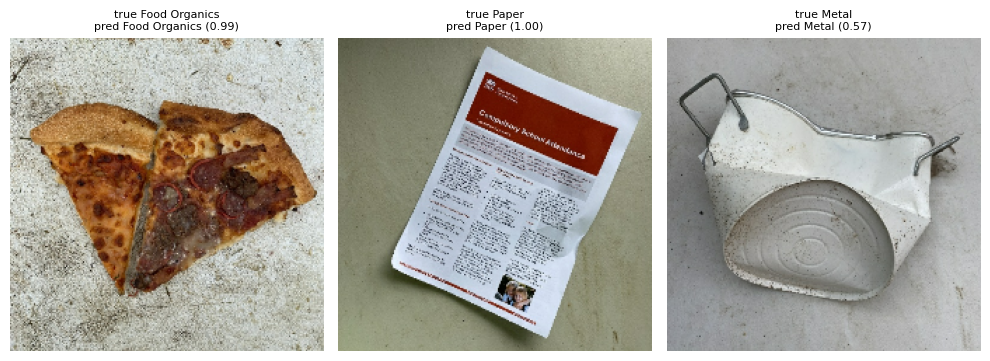


'greasy pizza box' -> Cardboard (1.00) low_confidence=False
   Cardboard recycling instructions. Accepted: Corrugated cardboard boxes; Paperboard (cereal boxes, etc.); Cardboard packaging; Cardboard tubes; Clean pizza boxes. Not accepted: Waxed cardboard; Cardboard with food residue; Cardboard with plastic linings; Foam i...

'dead AA batteries' -> Textile Trash (0.21) low_confidence=True
   Textile Trash recycling instructions. Accepted: Clean clothing (all conditions); Towels, sheets, and linens; Fabric scraps; Curtains and cloth napkins; Handbags and backpacks made of fabric; Soft toys and stuffed animals. Not accepted: Wet or moldy textiles; H...

'xylophone' -> Textile Trash (0.21) low_confidence=True
   Textile Trash recycling instructions. Accepted: Clean clothing (all conditions); Towels, sheets, and linens; Fabric scraps; Curtains and cloth napkins; Handbags and backpacks made of fabric; Soft toys and stuffed animals. Not accepted: Wet or moldy textiles; H...


In [ ]:
# 5.3  Evaluate the integrated system on test cases
# (a) Images: run the assistant on test-set images (arrays), compare to the true label.
N_IMG = 150; img_rows = []
for x, y in test_dataset:
    for xi, yi in zip(x.numpy(), np.argmax(y.numpy(), axis=1)):
        out = waste_management_assistant(xi, "image")
        img_rows.append(dict(true=IMG_CLASS_TO_CATEGORY[class_names[yi]], pred=out['category'], conf=out['confidence'], low=out['low_confidence']))
        if len(img_rows) >= N_IMG: break
    if len(img_rows) >= N_IMG: break
img_eval = pd.DataFrame(img_rows); img_eval['ok'] = img_eval.true == img_eval.pred

# (b) Text: run the assistant on every held-out description
txt_rows = []
for d, c in zip(X_test, y_test):
    out = waste_management_assistant(d, "text")
    txt_rows.append(dict(true=c, pred=out['category'], conf=out['confidence'], low=out['low_confidence']))
txt_eval = pd.DataFrame(txt_rows); txt_eval['ok'] = txt_eval.true == txt_eval.pred

summary = pd.DataFrame({
    'n': [len(img_eval), len(txt_eval)],
    'category accuracy': [img_eval.ok.mean(), txt_eval.ok.mean()],
    'mean confidence': [img_eval.conf.mean(), txt_eval.conf.mean()],
    'flagged low-confidence': [img_eval.low.mean(), txt_eval.low.mean()],
    'accuracy when NOT flagged': [img_eval[~img_eval.low].ok.mean(), txt_eval[~txt_eval.low].ok.mean()]}, index=['image', 'text']).round(4)
print(summary.to_string())

# (c) Generated instructions: are they grounded in the retrieved policy and free of policy violations?
rows = []
for cat in CATEGORIES:
    ans, docs = generate_recycling_instructions(cat); ctx, _ = build_context(cat, f"How to recycle {cat}")
    rows.append(dict(category=cat, grounded=round(groundedness(ans, ctx), 3), violation=policy_violation(ans, cat), top_policy=docs[0]['policy_type']))
print("\n", pd.DataFrame(rows).to_string(index=False))

# (d) End-to-end examples, including a mistake / uncertain case
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6)); shown = 0
for x, y in test_dataset.take(1):
    for xi, yi, ax in zip(x.numpy()[:3], np.argmax(y.numpy(), 1)[:3], axes):
        o = waste_management_assistant(xi, "image"); ax.imshow(xi.astype('uint8')); ax.axis('off')
        ax.set_title(f"true {IMG_CLASS_TO_CATEGORY[class_names[yi]]}\npred {o['category']} ({o['confidence']:.2f})", fontsize=8)
plt.tight_layout(); plt.show()
for q in ["greasy pizza box", "dead AA batteries", "xylophone"]:
    o = waste_management_assistant(q, "text")
    print(f"\n{q!r} -> {o['category']} ({o['confidence']:.2f}) low_confidence={o['low_confidence']}\n   {o['recycling_instructions'][:260]}...")

In [ ]:

# (e) Edge cases: the assistant must degrade gracefully instead of crashing
noise = Image.fromarray(np.random.default_rng(0).integers(0, 255, (300, 300, 3), dtype=np.uint8))
cases = [('missing image file', 'image', 'does/not/exist.jpg'), ('None as image', 'image', None), ('random-noise image', 'image', noise),
         ('RGBA image', 'image', Image.new('RGBA', (80, 60), (30, 120, 30, 128))),
         ('empty text', 'text', ''), ('numbers only', 'text', '12345'), ('gibberish', 'text', 'asdkjh qwpoei'), ('non-string text', 'text', 12345),
         ('not a waste item', 'text', 'my cat is sleeping on the sofa'), ('misspelling', 'text', 'empy plastc watr bottel'), ('bad input_type', 'audio', 'x')]
rows = []
for name, typ, data in cases:
    o = waste_management_assistant(data, typ)
    rows.append(dict(case=name, status=o['status'], category=o['category'], confidence=o['confidence'], note=o['note'][:70]))
print(pd.DataFrame(rows).to_string(index=False))


              case    status            category  confidence                                                                   note
missing image file     error                None         NaN Could not read the input (FileNotFoundError: [Errno 2] No such file or
     None as image     error                None         NaN Could not read the input (ValueError: 'images' must have either 3 or 4
random-noise image uncertain Miscellaneous Trash      0.3311 Low confidence - please check the item type before following these ste
        RGBA image uncertain               Metal      0.5020 Low confidence - please check the item type before following these ste
        empty text     error                None         NaN               Please provide a non-empty text description of the item.
      numbers only uncertain       Textile Trash      0.2062 Low confidence - please check the item type before following these ste
         gibberish uncertain       Textile Trash      0.2062 Low confidence 

## Design decisions, and  findings

**What was built.** (1) MobileNetV2 transfer-learning CNN for the nine RealWaste classes; (2) TF-IDF + logistic-regression text classifier; (3) retrieval-augmented Flan-T5 generator fine-tuned to produce structured instructions from retrieved Metro City policy text; (4) an assistant that routes an image or text through (1) or (2) into (3).

**Key design choices and why.**
- *CNN*: frozen ImageNet features first, then a short low-learning-rate fine-tune of the top layers. Dropout, L2, augmentation, class weights and early stopping address over-fitting on a few thousand images. The model is selected on validation accuracy; the test set is used only to report.
- *Text model*: the descriptions are short and keyword driven, so a linear model on word/bigram features is competitive with a transformer at a fraction of the cost. Duplicates were removed before splitting to avoid leakage.
- *RAG*: policies are chunked by section, tagged with a category, and ranked by embedding similarity plus a bonus for dedicated single-category policies. The generator sees only the retrieved context, and training targets are built only from that context, so it learns to copy policy rather than recall it.



## Challenges, design decisions and limitations

### 1. Mismatches between the brief and the data
- **Class count.** The brief describes 8 classes, but RealWaste and `waste_descriptions.csv` both contain 9 (Cardboard, Food Organics, Glass, Metal, Miscellaneous Trash, Paper, Plastic, Textile Trash, Vegetation). I used all 9 and added an assertion that the image labels and text labels match exactly.
- **Policy file format.** The brief refers to `waste_policy_documents.csv`; the supplied file is JSON, so I loaded it as JSON.
- **Incomplete dataset copy.** My first copy on Google Drive was incomplete (1,168 of 4,752 images; six classes had zero files) because the folder upload stopped part-way. I now locate or download a complete copy on the local Colab disk and check the image count before continuing.

### 2. Train/validation/test split bug (most important finding)
- **Symptom.** The test set contained only Plastic, Textile Trash and Vegetation. Accuracy looked high (0.946) but macro-F1 was only 0.36, and `classification_report` failed with "8 classes vs 9 target names".
- **Cause.** With `shuffle=False`, `validation_split` does not shuffle the file list, so the hold-out set was the last 20 % of files in alphabetical order. The training subset came from a differently ordered list, so the two overlapped, which is data leakage.
- **Fix.** I split the file list once, stratified by class, with a fixed seed (70 / 15 / 15). Checks confirm that the splits are disjoint and that every class appears in every split.
- **Consequence.** All earlier CNN results were invalid and the model was retrained from scratch.

### 3. Compute and memory limits
- **CPU runtime.** Training was about 10x too slow until I switched Colab to a T4 GPU.
- **Session crashes.** The session ran out of RAM, and TensorFlow reserves the whole GPU by default, which left no room for PyTorch (Flan-T5) in the same process. I enabled TensorFlow memory growth, freed old models before loading the generator, and made the pipeline configurable with `DATA_FRACTION`, a cache mode (`'ram'`, `'disk'` or `None`), a smaller batch size and a `LOW_MEMORY` option (Flan-T5-small).
- **Runtime restarts.** A restart clears all variables, so the notebook must be run from top to bottom (a later cell run alone raised `NameError: CATEGORIES`).

### 4. Results after fixing the split
- The CNN (MobileNetV2, transfer learning) reached **test accuracy 0.816 and macro-F1 0.821**, much lower than the leaky 0.946.
- Fine-tuning the top 40 layers did **not** help (validation accuracy 0.7994 for the baseline vs 0.7966 after fine-tuning).
- The hardest classes were Miscellaneous Trash (recall 0.57), Plastic (0.72) and Glass (0.76). The most frequent confusion was Plastic predicted as Glass (18 images), which is plausible because transparent plastic and glass look alike.
- **Next steps.** A larger fine-tuning learning rate, more unfrozen layers, lighter augmentation or a stronger base model such as EfficientNet.

### 5. Data quality and limitations
- **Templated text.** The descriptions are generated from a template with only about 300 distinct words, so near-perfect text accuracy mainly shows that the template was learned. I therefore added a small hand-written stress set of natural phrasings, which is a better indicator of real-world performance (it is small and labelled by me, so it is a sanity check, not a benchmark).
- **Decoy material words.** Some descriptions contain a misleading material word (for example "glass old t-shirt" is Textile Trash). These account for the few genuine text errors.
- **Duplicates.** Duplicate descriptions were removed before splitting so that no sentence appears in both training and test data.
- **Policy contradictions.** The combined policy documents list items such as plastic bags and window glass as acceptable, while the category-specific documents list them as not accepted. I treated the category-specific documents as authoritative because they are the only ones with explicit "non-acceptable" lists, and the `common_confusion` text in the CSV agrees. The city should confirm this before deployment.
- **Dataset bias.** RealWaste comes from a single facility and camera set-up, so accuracy on resident phone photos is likely to be lower than reported here. The assistant therefore flags low-confidence predictions instead of guessing.

### 6. Design choices that follow from these challenges
- **Verified generation.** Flan-T5 answers are checked against the policy knowledge base, and an extractive answer built directly from the retrieved policy text is returned when the check fails.
- **Graceful errors.** Bad input (missing file, empty text, wrong type) returns a clear error status rather than raising an exception.
- **Feedback loop.** The assistant logs user feedback so that corrections can feed future retraining.

- *Synthetic text data.* Descriptions are generated from templates, so test accuracy on them is likely to be near-perfect and over-states real-world performance. The out-of-template probes in 3.3 show how the model behaves on phrasings it has not seen.
- *Policy conflicts.* Some combined policies (e.g. Residential, Municipal) list items that the dedicated policies exclude (plastic bags and film, window glass), and in some cases the combined policy has the later effective date. The system follows the dedicated policy and returns the other documents as references; Metro City should confirm which prevails.
- *Image categories.* Visually similar classes (paper/cardboard, plastic/miscellaneous trash, food organics/vegetation) are the expected confusions; check the confusion matrix and error gallery from 2.3/2.4.
- *Generator size.* A 250M-parameter model can still drop or reword an item; the groundedness and policy-violation checks in 4.3 are the safeguard, and a production system should validate generated lists against the policy text before showing them.